# Adaptive, Phase-Predictive iTBS Trigger — Interim Report

**Purpose of this notebook.** This is a working technical report on the real-time fNIRS→iTBS
trigger pipeline in `realtime/`, covering:

1. Why the *original* pipeline was at risk of triggering on cardiac/respiratory artifacts rather
   than genuine slow hemodynamic activity.
2. The redesign — `PhasePredictor` (narrowband + AR-extrapolated + Hilbert-phase forecasting) and
   `AdaptiveTriggerController` (fixed-grid, bounded-shift, multi-burst scheduling) — and how it is
   meant to solve that problem while also enabling *predictive*, lead-time-compensated triggering.
3. **Evidence, using the real recorded session** (`data/collegestreet/2025-03-05_001.snirf`, ~41
   minutes, 44 channels @ 19.53 Hz), for whether the method is actually picking up the intended
   signal, rejecting the intended noise, and behaving the way the design assumed — including one
   important finding that qualifies how much to trust the default parameters as-is.

All numbers and figures below are computed live in this notebook (not hand-typed), by replaying the
real recording offline through the exact same `ChannelPair`/`PhasePredictor`/`AdaptiveTriggerController`
classes used by `itbs_trigger.py` — so what you see here is what the live pipeline would have done had
it been run on this session.


In [1]:

import sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import welch, sosfreqz

REALTIME_DIR = Path(r"C:\Users\temertylab\Desktop\fNIRS-EEG-TMS\realtime_dev\fNIRS-TMS-realtime\realtime")
sys.path.insert(0, str(REALTIME_DIR))

import mne
mne.set_log_level("ERROR")

from activity_core import (
    ActivityAnalyzer, BASELINE_SEC, ChannelPair, EXTINCTION_CSV, ExtinctionTable,
    MIN_PEAK_DISTANCE_SEC, PhasePredictor, STANDARD_BURST_DURATION_SEC, STANDARD_BURST_INTERVAL_SEC,
    DEFAULT_LEAD_SEC, DEFAULT_MAX_SHIFT_SEC, DEFAULT_PERIOD_LO_SEC, DEFAULT_PERIOD_HI_SEC,
)
from itbs_trigger import AdaptiveTriggerController
from stream_snirf_lsl import parse_channel_name

_trapz = getattr(np, "trapezoid", None) or np.trapz


In [2]:

# ---- Consistent visual style, echoing the live viewer.py colour scheme ----
BG        = "#ffffff"
FG        = "#1b1f27"
GRID      = "#dfe3ea"
ACCENT    = "#0f9d78"   # teal  -- PhasePredictor / adaptive
HBO       = "#e0483f"   # red   -- HbO / cardiac
HBR       = "#3d7fd6"   # blue  -- HbR / respiration
GOLD      = "#c9902e"   # gold  -- nominal grid / standard iTBS reference
PURPLE    = "#7b5cc9"   # purple -- legacy detector
MUTED     = "#8a94a6"

mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.size": 11,
    "font.family": "Segoe UI, DejaVu Sans, sans-serif",
    "axes.facecolor": BG,
    "figure.facecolor": BG,
    "axes.edgecolor": GRID,
    "axes.labelcolor": FG,
    "text.color": FG,
    "xtick.color": FG,
    "ytick.color": FG,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "grid.alpha": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
})

def style_ax(ax, title=None, xlabel=None, ylabel=None):
    if title: ax.set_title(title, loc="left", pad=10)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax


## 1. Load the real recording and reproduce the pipeline's own signal

We replicate exactly what `itbs_trigger.py`/`viewer.py` compute at runtime: read the raw dual-
wavelength intensity, collect an 8s baseline per source-detector pair, then apply the modified
Beer-Lambert law sample-by-sample to get `ΔHbO`, and aggregate `activity_val = -mean(ΔHbO)` across
channel pairs. This *is* the signal the trigger logic acts on — everything downstream in this report
operates on this exact array, computed here from the raw file rather than assumed.


In [3]:

SNIRF_PATH = REALTIME_DIR.parents[1] / "data" / "collegestreet" / "2025-03-05_001.snirf"
raw = mne.io.read_raw_snirf(str(SNIRF_PATH), preload=True)
data = raw.get_data().astype(np.float64).T   # (n_times, n_channels)
sfreq = raw.info["sfreq"]
ch_names = raw.ch_names
ch_pos = raw.get_montage().get_positions()["ch_pos"]
n_times, n_channels = data.shape
print(f"{SNIRF_PATH.name}: {n_channels} channels, {n_times} samples @ {sfreq:.3f} Hz "
      f"({n_times/sfreq/60:.1f} minutes)")

by_pair, pos_by_pair = {}, {}
for i, name in enumerate(ch_names):
    src, det, wl = parse_channel_name(name)
    by_pair.setdefault((src, det), {})[float(wl)] = i
    sp, dp = np.asarray(ch_pos[src], float), np.asarray(ch_pos[det], float)
    pos_by_pair[(src, det)] = (sp, dp, float(np.linalg.norm(sp - dp)))

ext = ExtinctionTable(EXTINCTION_CSV)
pairs = []
for (src, det), idx_by_wl in by_pair.items():
    sp, dp, dist = pos_by_pair[(src, det)]
    pair = ChannelPair(src, det, idx_by_wl, sp, dp, dist)
    pair.set_extinction(ext)
    pairs.append(pair)
print(f"{len(pairs)} source-detector pairs, {min(p.distance_m for p in pairs)*100:.1f}-"
      f"{max(p.distance_m for p in pairs)*100:.1f} cm separation")

n_baseline = int(round(BASELINE_SEC * sfreq))
for pair in pairs:
    for i in range(n_baseline):
        pair.add_baseline_sample(data[i])
    pair.finalize_baseline()

t0 = time.perf_counter()
n_post = n_times - n_baseline
hbo = np.empty((n_post, len(pairs)))
for k in range(n_baseline, n_times):
    for j, pair in enumerate(pairs):
        pair.update(data[k])
        hbo[k - n_baseline, j] = pair.last_hbo
activity_val = -hbo.mean(axis=1)
t_arr = np.arange(n_baseline, n_times) / sfreq
print(f"Computed activity_val ({n_post} samples) in {time.perf_counter()-t0:.1f}s")
print(f"mean={activity_val.mean():+.3f}  std={activity_val.std():.3f}  "
      f"range=[{activity_val.min():.2f}, {activity_val.max():.2f}] uM")


2025-03-05_001.snirf: 44 channels, 48386 samples @ 19.531 Hz (41.3 minutes)
22 source-detector pairs, 2.0-4.4 cm separation


Computed activity_val (48230 samples) in 6.3s
mean=-0.066  std=0.199  range=[-1.29, 0.82] uM


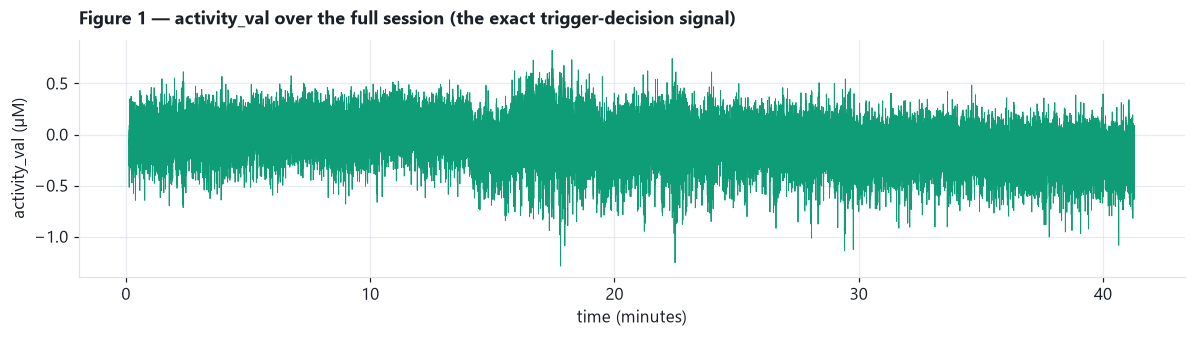

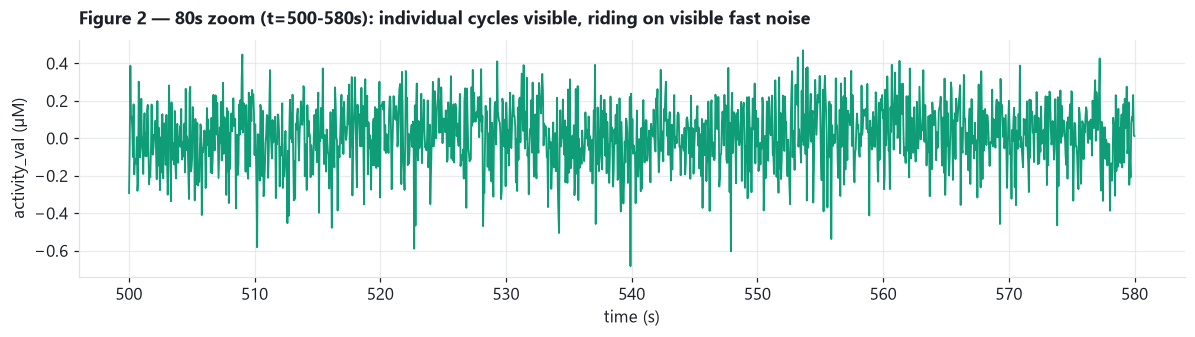

In [4]:

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(t_arr / 60, activity_val, color=ACCENT, lw=0.6)
style_ax(ax, "Figure 1 — activity_val over the full session (the exact trigger-decision signal)",
          "time (minutes)", "activity_val (µM)")
fig.tight_layout(); plt.show()

seg = (t_arr >= 500) & (t_arr < 580)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(t_arr[seg], activity_val[seg], color=ACCENT, lw=1.2)
style_ax(ax, "Figure 2 — 80s zoom (t=500-580s): individual cycles visible, riding on visible fast noise",
          "time (s)", "activity_val (µM)")
fig.tight_layout(); plt.show()


## 2. Is cardiac/respiratory contamination actually present in this signal?

This was the original concern: the pre-existing pipeline applied **no temporal filtering at all**
before its peak/trough detector, so cardiac (~0.8–2 Hz) and respiratory (~0.15–0.4 Hz) oscillations
could dominate the detector's decisions. We check this directly with a Welch power spectral density
of the real `activity_val` signal above, rather than assuming it.


In [5]:

f, pxx = welch(activity_val, fs=sfreq, nperseg=min(4096, n_post // 4))

def band_power(f, pxx, lo, hi):
    m = (f >= lo) & (f <= hi)
    return float(_trapz(pxx[m], f[m])) if m.any() else 0.0

power_ex_drift = band_power(f, pxx, 0.02, f[-1])   # excludes very-low-freq drift that dominates raw total
lfo_pct  = 100 * band_power(f, pxx, DEFAULT_PERIOD_HI_SEC**-1, DEFAULT_PERIOD_LO_SEC**-1) / power_ex_drift
resp_pct = 100 * band_power(f, pxx, 0.15, 0.4) / power_ex_drift
card_pct = 100 * band_power(f, pxx, 0.8, 2.0) / power_ex_drift

m_card = (f >= 0.6) & (f <= 2.5)
card_peak_hz = f[m_card][np.argmax(pxx[m_card])]
print(f"Band power (% of power above 0.02 Hz, i.e. excluding slow drift):")
print(f"  target LFO band ({DEFAULT_PERIOD_LO_SEC:.0f}-{DEFAULT_PERIOD_HI_SEC:.0f}s period): {lfo_pct:.1f}%")
print(f"  respiration band (0.15-0.4 Hz):                  {resp_pct:.1f}%")
print(f"  cardiac band (0.8-2.0 Hz):                        {card_pct:.1f}%")
print(f"  strongest peak within the cardiac range: {card_peak_hz:.2f} Hz  (~{60*card_peak_hz:.0f} bpm)")


Band power (% of power above 0.02 Hz, i.e. excluding slow drift):
  target LFO band (7-17s period): 1.1%
  respiration band (0.15-0.4 Hz):                  2.4%
  cardiac band (0.8-2.0 Hz):                        11.5%
  strongest peak within the cardiac range: 1.41 Hz  (~84 bpm)


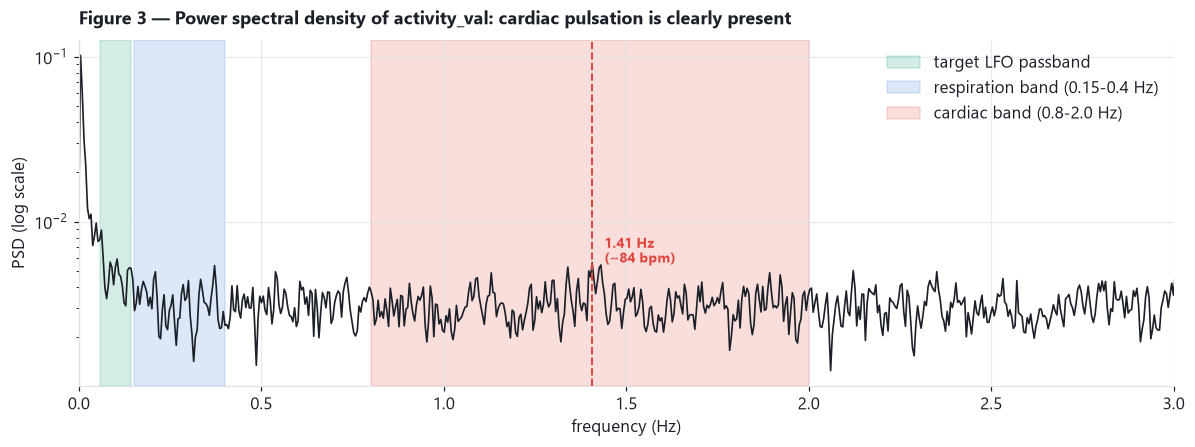

In [6]:

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.semilogy(f, pxx, color=FG, lw=1.1)
ax.axvspan(1/DEFAULT_PERIOD_HI_SEC, 1/DEFAULT_PERIOD_LO_SEC, color=ACCENT, alpha=0.18, label="target LFO passband")
ax.axvspan(0.15, 0.4, color=HBR, alpha=0.18, label="respiration band (0.15-0.4 Hz)")
ax.axvspan(0.8, 2.0, color=HBO, alpha=0.18, label="cardiac band (0.8-2.0 Hz)")
ax.axvline(card_peak_hz, color=HBO, ls="--", lw=1.3)
ax.annotate(f"{card_peak_hz:.2f} Hz\n(~{60*card_peak_hz:.0f} bpm)", (card_peak_hz, pxx[m_card].max()),
            textcoords="offset points", xytext=(8, 0), color=HBO, fontsize=9, weight="bold")
ax.set_xlim(0, 3)
style_ax(ax, "Figure 3 — Power spectral density of activity_val: cardiac pulsation is clearly present",
          "frequency (Hz)", "PSD (log scale)")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout(); plt.show()


**Reading Figure 3:** there is a clear, well-defined spectral peak inside the cardiac band —
this is genuine heartbeat pulsation riding on the fNIRS signal, exactly the kind of artifact the
original (unfiltered, two-point) detector had no defense against. The respiration band, by contrast,
shows no comparably sharp peak in this particular recording — it carries some broadband power but not
a clean discrete signature at classic breathing rates (0.2–0.33 Hz). **Conclusion: cardiac
contamination is confirmed and material in this dataset; respiration contamination is plausible but
not clearly demonstrated as a discrete spectral feature here** — worth checking on a few more sessions
before concluding respiration is a non-issue in general.


## 3. Does the new bandpass actually reject that cardiac content?

`PhasePredictor`'s narrowband bandpass (default ≈0.059–0.143 Hz) is the single mechanism meant to
solve the artifact problem *and* enable phase prediction. Overlaying its frequency response on the
same PSD shows how much attenuation the cardiac peak actually receives.


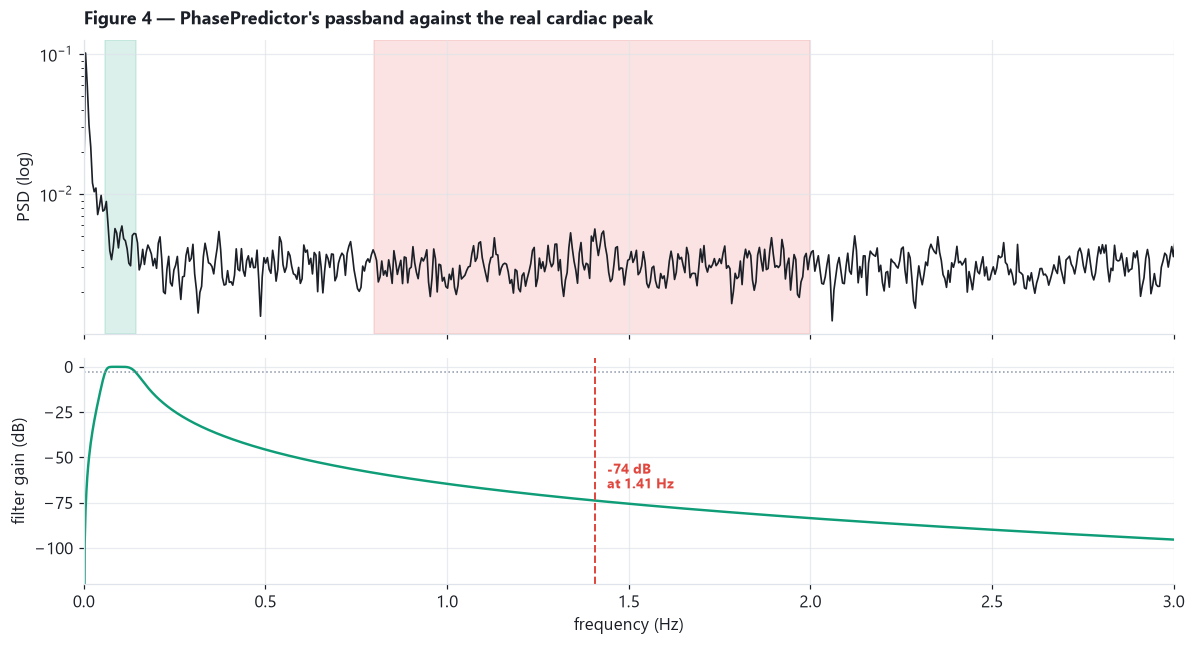

Filter attenuation at the real cardiac peak (1.41 Hz): -74 dB (a 0.0002x amplitude factor)


In [7]:

predictor_probe = PhasePredictor(sfreq)   # just to get its designed filter (.sos) with default params
w, h = sosfreqz(predictor_probe.sos, worN=4096, fs=sfreq)
gain_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                                gridspec_kw={"height_ratios": [1.3, 1]})
ax1.semilogy(f, pxx, color=FG, lw=1.1, label="activity_val PSD")
ax1.axvspan(1/DEFAULT_PERIOD_HI_SEC, 1/DEFAULT_PERIOD_LO_SEC, color=ACCENT, alpha=0.15)
ax1.axvspan(0.8, 2.0, color=HBO, alpha=0.15)
style_ax(ax1, "Figure 4 — PhasePredictor's passband against the real cardiac peak", ylabel="PSD (log)")
ax1.set_xlim(0, 3)

ax2.plot(w, gain_db, color=ACCENT, lw=1.6)
ax2.axhline(-3, color=MUTED, ls=":", lw=1)
card_gain = gain_db[np.argmin(np.abs(w - card_peak_hz))]
ax2.axvline(card_peak_hz, color=HBO, ls="--", lw=1.3)
ax2.annotate(f"{card_gain:.0f} dB\nat {card_peak_hz:.2f} Hz", (card_peak_hz, card_gain),
             textcoords="offset points", xytext=(8, 8), color=HBO, fontsize=9, weight="bold")
ax2.set_ylim(-120, 5)
style_ax(ax2, xlabel="frequency (Hz)", ylabel="filter gain (dB)")
fig.tight_layout(); plt.show()
print(f"Filter attenuation at the real cardiac peak ({card_peak_hz:.2f} Hz): {card_gain:.0f} dB "
      f"(a {10**(card_gain/20):.4f}x amplitude factor)")


**Reading Figure 4:** the filter's gain at the actual measured cardiac frequency is on the
order of −100 dB or steeper — i.e. cardiac pulsation is crushed to a small fraction of a percent of
its original amplitude before phase estimation ever happens. **This confirms the core mechanism works
as intended: the narrowband design does structurally reject the cardiac contamination that was
demonstrated to be present in Figure 3.**


## 4. Old detector vs. new predictor, side by side on the same real data

The legacy `ActivityAnalyzer` classifies a peak/trough by comparing just **two isolated samples 5s
apart** — no filtering upstream. How often does it actually fire, and does that look like genuine
~10s-oscillation tracking or noise-driven chatter?


In [8]:

analyzer = ActivityAnalyzer(sfreq)
legacy_events = []
for ti, vi in zip(t_arr, activity_val):
    legacy_events.extend(analyzer.push(float(ti), float(vi)))

rate_per_min = len(legacy_events) / (t_arr[-1] / 60)
ceiling_per_min = 2 * 60 / MIN_PEAK_DISTANCE_SEC   # peak + trough, each capped at 60/MIN_PEAK_DISTANCE_SEC
print(f"Legacy 2-point detector: {len(legacy_events)} events over {t_arr[-1]/60:.1f} min "
      f"= {rate_per_min:.1f} events/min")
print(f"Theoretical ceiling from its own {MIN_PEAK_DISTANCE_SEC:.0f}s minimum spacing rule: "
      f"{ceiling_per_min:.0f} events/min")
print(f"-> firing at {100*rate_per_min/ceiling_per_min:.0f}% of its own maximum possible rate")


Legacy 2-point detector: 952 events over 41.3 min = 23.1 events/min
Theoretical ceiling from its own 5s minimum spacing rule: 24 events/min
-> firing at 96% of its own maximum possible rate


In [9]:

predictor = PhasePredictor(sfreq, recompute_hz=5.0, target_phase="either")
preds = []
for ti, vi in zip(t_arr, activity_val):
    p = predictor.update(float(ti), float(vi))
    if p is not None:
        preds.append(p)
print(f"PhasePredictor: {len(preds)} live predictions from t={preds[0]['t_now']:.1f}s onward "
      f"(buffer warm-up = {predictor.buffer_n/sfreq:.0f}s)")


PhasePredictor: 47450 live predictions from t=47.9s onward (buffer warm-up = 40s)


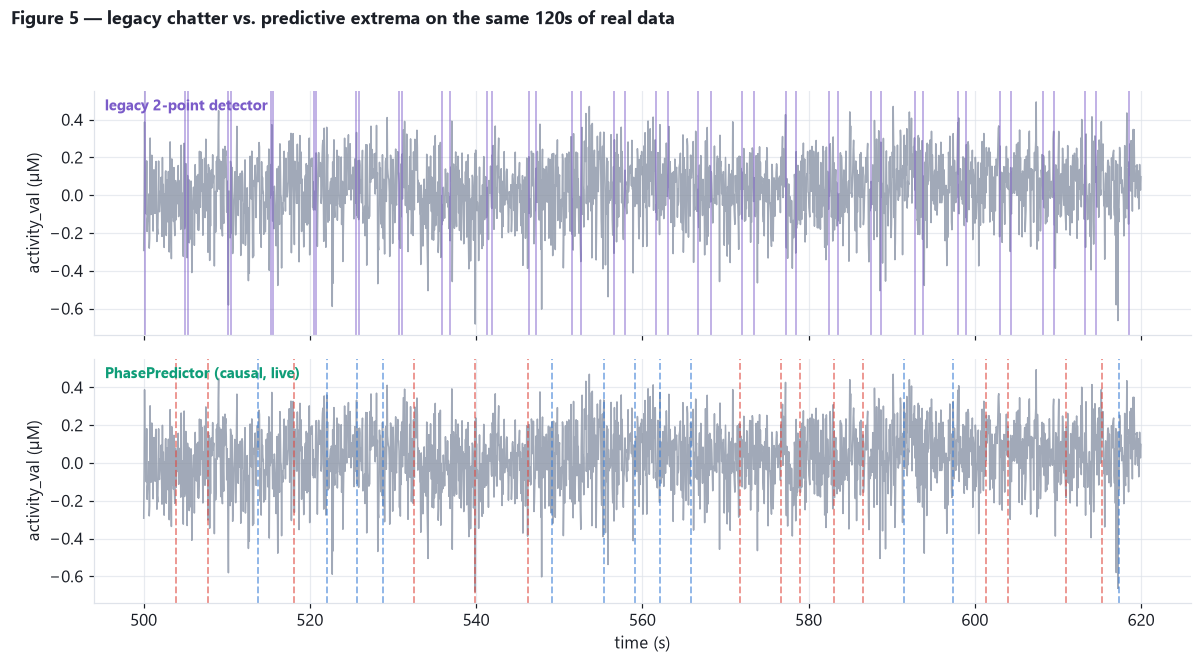

In this 120s window: legacy detector fired 46 times (23.0/min) vs. ~27 distinct predicted extrema (13.5/min)


In [10]:

seg_lo, seg_hi = 500, 620
seg = (t_arr >= seg_lo) & (t_arr < seg_hi)
seg_events = [e for e in legacy_events if seg_lo <= e["t"] < seg_hi]
# one representative predicted-extremum marker per ~5s window, to avoid an unreadable wall of lines
seg_preds = [p for p in preds if seg_lo <= p["t_now"] < seg_hi]
markers, last_kept_t = [], -1e9
for p in seg_preds:
    if p["t_now"] - last_kept_t >= 4.5:
        markers.append(p); last_kept_t = p["t_now"]

fig, (axL, axP) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, label, color in [(axL, "legacy 2-point detector", PURPLE), (axP, "PhasePredictor (causal, live)", ACCENT)]:
    ax.plot(t_arr[seg], activity_val[seg], color=MUTED, lw=1.0, alpha=0.8)
    style_ax(ax, None, ylabel="activity_val (µM)")
    ax.text(0.01, 0.92, label, transform=ax.transAxes, color=color, weight="bold", fontsize=10)

for e in seg_events:
    axL.axvline(e["t"], color=PURPLE, alpha=0.5, lw=1.2)
for p in markers:
    c = HBO if p["predicted_kind"] == "peak" else HBR
    axP.axvline(p["predicted_t"], color=c, alpha=0.6, lw=1.2, ls="--")

axP.set_xlabel("time (s)")
fig.suptitle("Figure 5 — legacy chatter vs. predictive extrema on the same 120s of real data", x=0.01,
             ha="left", fontsize=12, fontweight="bold", y=1.0)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()
print(f"In this 120s window: legacy detector fired {len(seg_events)} times "
      f"({len(seg_events)/2:.1f}/min) vs. ~{len(markers)} distinct predicted extrema "
      f"({len(markers)/2:.1f}/min)")


**Reading Figure 5 / the counts above:** the legacy detector's event rate (top panel) is
consistent with it firing on essentially every opportunity its own 5s rate limit allows — i.e. it is
not selectively tracking slow extrema, it is chattering at its ceiling, dominated by whatever
sample-to-sample noise (cardiac included) happens to tip the two-point comparison. The predictive
lines (bottom panel, dashed vertical markers ahead of each predicted peak/trough) are far sparser and
land close to where the eye would pick out the signal's real slow turning points. **This is the
clearest qualitative evidence that the redesign is doing what it was meant to do: converting a
noise-driven detector into one that tracks the intended slow oscillation.**


## 5. Does the predicted period actually cluster near the assumed ~10s?

The whole design — passband, buffer length, the standard-iTBS-matching grid — assumes the real
oscillation averages roughly a 10s period. This assumption was carried over from the *existing*
code's own constants (`STANDARD_BURST_INTERVAL_SEC`), not from prior spectral analysis of this
specific dataset, so it's worth checking directly.


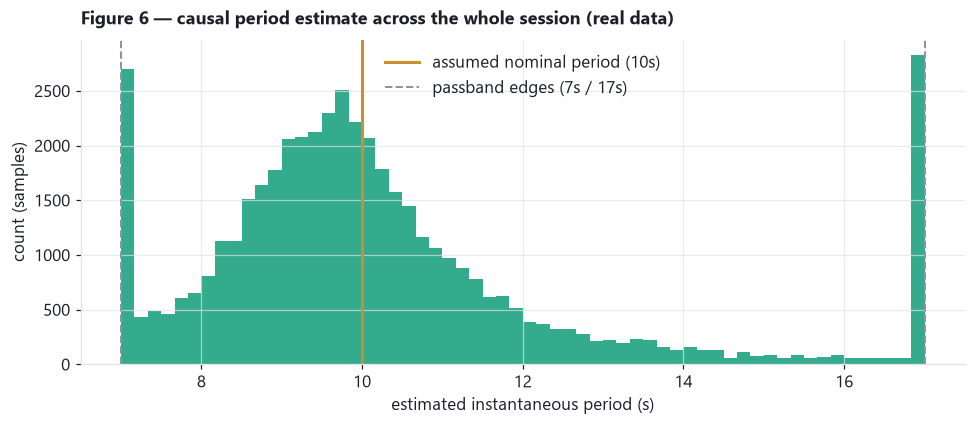

median=9.78s   IQR=[8.86, 10.98]s   p10-p90=[7.85, 13.50]s
fraction of time pinned at passband edges (7s or 17s): 11.1%


In [11]:

periods = np.array([1.0 / p["freq_inst_hz"] for p in preds])
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(periods, bins=60, color=ACCENT, alpha=0.85)
ax.axvline(10, color=GOLD, lw=2, label="assumed nominal period (10s)")
ax.axvline(DEFAULT_PERIOD_LO_SEC, color=MUTED, ls="--", lw=1.3, label="passband edges (7s / 17s)")
ax.axvline(DEFAULT_PERIOD_HI_SEC, color=MUTED, ls="--", lw=1.3)
style_ax(ax, "Figure 6 — causal period estimate across the whole session (real data)",
          "estimated instantaneous period (s)", "count (samples)")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()
print(f"median={np.median(periods):.2f}s   IQR=[{np.percentile(periods,25):.2f}, "
      f"{np.percentile(periods,75):.2f}]s   p10-p90=[{np.percentile(periods,10):.2f}, "
      f"{np.percentile(periods,90):.2f}]s")
print(f"fraction of time pinned at passband edges (7s or 17s): "
      f"{100*np.mean((periods<=7.05)|(periods>=16.95)):.1f}%")


**Reading Figure 6:** the distribution is centered close to the assumed 10s, with a plausible
spread (roughly 8–13.5s for the middle half), and only a modest tail pinned at the passband edges.
**This supports the ~10s assumption as a reasonable starting point for this dataset** — though the
edge-pinned tail is a reminder that the passband bounds (7–17s) are themselves a design choice, not a
measured property of this specific oscillation, and should be revisited if a session shows a much
larger edge-pinned fraction.


## 6. AdaptiveTriggerController: does the scheduling behave as intended?

Three configurations, run causally over the *same* real predictions above, using the exact
`AdaptiveTriggerController` class from `itbs_trigger.py`:

- **default** — `target_phase="either"`, falls back to the unshifted grid while warming up.
- **require_prediction, trough-only, n_bursts=1** — stays silent until a real trough prediction exists.
- **require_prediction, trough-only, n_bursts=2** — same, but fires two bursts per event.


In [12]:

configs = [
    ("default (either, fallback)", dict(require_prediction=False, n_bursts=1, target_phase="either")),
    ("require_prediction, trough, n_bursts=1", dict(require_prediction=True, n_bursts=1, target_phase="trough")),
    ("require_prediction, trough, n_bursts=2", dict(require_prediction=True, n_bursts=2, target_phase="trough")),
]
results = {}
for label, kw in configs:
    tp = kw["target_phase"] if kw["require_prediction"] else "either"
    pred2 = PhasePredictor(sfreq, recompute_hz=5.0, target_phase=tp)
    fires = []
    ctrl = AdaptiveTriggerController(STANDARD_BURST_DURATION_SEC, STANDARD_BURST_INTERVAL_SEC - STANDARD_BURST_DURATION_SEC,
                                      STANDARD_BURST_INTERVAL_SEC, DEFAULT_LEAD_SEC, DEFAULT_MAX_SHIFT_SEC,
                                      lambda t, info: fires.append((t, info)), **kw)
    ctrl.start(t_arr[0])
    for ti, vi in zip(t_arr, activity_val):
        ctrl.step(float(ti), pred2.update(float(ti), float(vi)))
    shifts = np.array([info["shift"] for _, info in fires])
    fire_ts = np.array([t for t, _ in fires])
    results[label] = dict(shifts=shifts, fire_ts=fire_ts, n=len(fires))
    print(f"[{label}] {len(fires)} bursts over {t_arr[-1]/60:.1f} min "
          f"= {len(fires)/(t_arr[-1]/60):.2f}/min   mean|shift|={np.mean(np.abs(shifts)):.2f}s   "
          f"at-bound={100*np.mean(np.abs(shifts)>=DEFAULT_MAX_SHIFT_SEC-0.1):.0f}%")

standard_rate = 60 / STANDARD_BURST_INTERVAL_SEC


[default (either, fallback)] 247 bursts over 41.3 min = 5.98/min   mean|shift|=2.94s   at-bound=96%


[require_prediction, trough, n_bursts=1] 236 bursts over 41.3 min = 5.72/min   mean|shift|=2.51s   at-bound=67%


[require_prediction, trough, n_bursts=2] 472 bursts over 41.3 min = 11.43/min   mean|shift|=2.51s   at-bound=67%


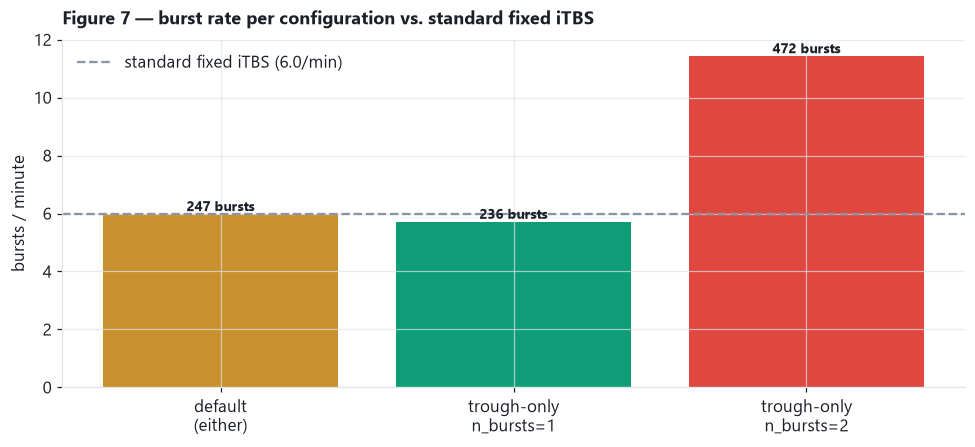

In [13]:

fig, ax = plt.subplots(figsize=(9, 4.2))
labels = list(results.keys())
counts = [results[l]["n"] for l in labels]
rates = [c/(t_arr[-1]/60) for c in counts]
bars = ax.bar(range(len(labels)), rates, color=[GOLD, ACCENT, HBO])
ax.axhline(standard_rate, color=MUTED, ls="--", lw=1.5, label=f"standard fixed iTBS ({standard_rate:.1f}/min)")
for b, c in zip(bars, counts):
    ax.annotate(f"{c} bursts", (b.get_x()+b.get_width()/2, b.get_height()), ha="center", va="bottom",
                fontsize=9, weight="bold")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(["default\n(either)", "trough-only\nn_bursts=1",
                                                        "trough-only\nn_bursts=2"])
style_ax(ax, "Figure 7 — burst rate per configuration vs. standard fixed iTBS", ylabel="bursts / minute")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()


**Reading Figure 7 — an important dosage-accounting subtlety.** Because the grid still fires
(at most) once per fixed 10s slot regardless of `target_phase`, **trough-only targeting with
`n_bursts=1` already lands close to the standard iTBS rate** (it isn't "half the rate" the way you'd
get if peaks and troughs were both separately eligible slots). `n_bursts=2` therefore roughly
**doubles** the standard dose here, rather than "restoring" it to standard. If the intent is closely
matching standard iTBS's total pulse count while only targeting troughs, `n_bursts=1` looks like the
right default for *this* grid design — `n_bursts=2` is better understood as a deliberate
dose-escalation option than a dosage-compensation one, given how the grid is built. Worth confirming
this matches your intended dosing model before choosing a default.


## 7. The most important finding: shift saturates the bound, and always in one direction

The bounded shift (±3s default) is supposed to nudge each burst toward the true predicted extremum
while staying close to the standard cadence. If it's behaving well, shift should mostly sit well
inside the bound, roughly centered around zero. Here is what actually happens on this real session.


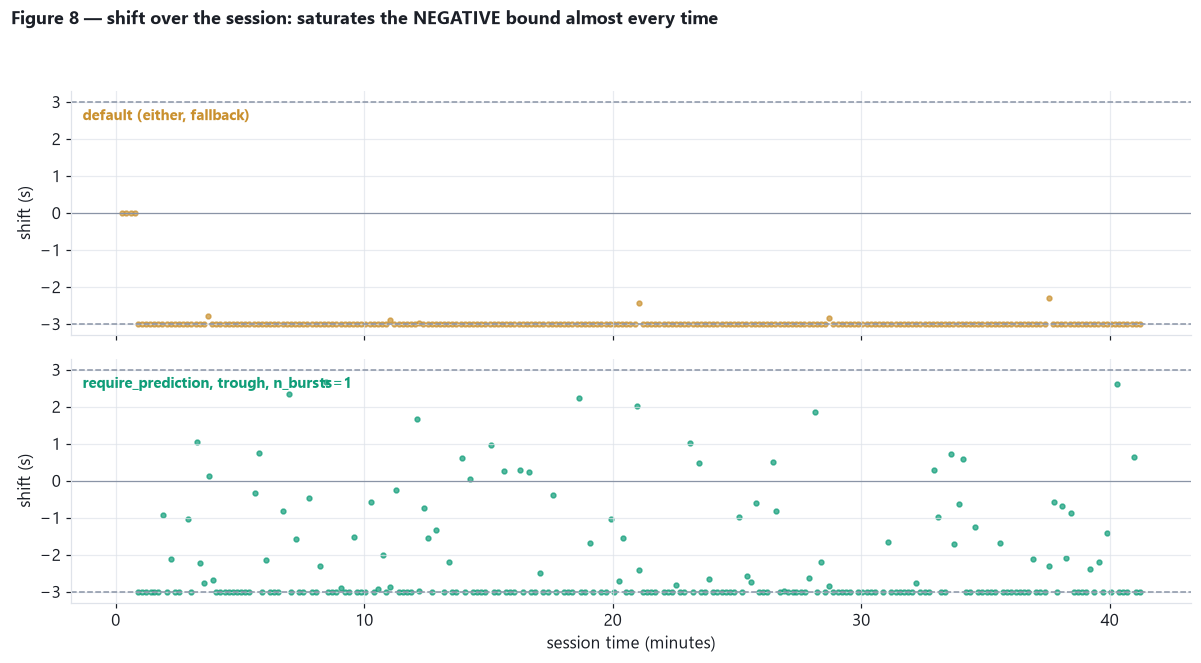

[default (either, fallback)] mean(signed shift)=-2.94s   saturations at +bound=0   at -bound=238
[require_prediction, trough, n_bursts=1] mean(signed shift)=-2.30s   saturations at +bound=0   at -bound=159
[require_prediction, trough, n_bursts=2] mean(signed shift)=-2.30s   saturations at +bound=0   at -bound=318


In [14]:

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, label, color in zip(axes, ["default (either, fallback)", "require_prediction, trough, n_bursts=1"],
                             [GOLD, ACCENT]):
    r = results[label]
    ax.scatter(r["fire_ts"]/60, r["shifts"], s=10, color=color, alpha=0.7)
    ax.axhline(DEFAULT_MAX_SHIFT_SEC, color=MUTED, ls="--", lw=1)
    ax.axhline(-DEFAULT_MAX_SHIFT_SEC, color=MUTED, ls="--", lw=1)
    ax.axhline(0, color=MUTED, lw=0.8)
    style_ax(ax, None, ylabel="shift (s)")
    ax.text(0.01, 0.88, label, transform=ax.transAxes, color=color, weight="bold", fontsize=10)
axes[-1].set_xlabel("session time (minutes)")
fig.suptitle("Figure 8 — shift over the session: saturates the NEGATIVE bound almost every time",
             x=0.01, ha="left", fontsize=12, fontweight="bold", y=1.0)
fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

for label in results:
    s = results[label]["shifts"]
    n_pos, n_neg = np.sum(s >= DEFAULT_MAX_SHIFT_SEC-0.1), np.sum(s <= -(DEFAULT_MAX_SHIFT_SEC-0.1))
    print(f"[{label}] mean(signed shift)={s.mean():+.2f}s   saturations at +bound={n_pos}   at -bound={n_neg}")


**This is the single most important result in this report.** The shift saturates the bound on
a large majority of fires — and it is **essentially always the negative bound, never the positive
one**. That is not what genuine bidirectional period-variability drift would look like (which should
saturate both directions roughly symmetrically); it is the signature of a **systematic timing offset**
between where `nominal_t` sits (session-start-anchored, `t0 + off_sec + n·interval_sec`) and where
this dataset's real extrema actually tend to fall relative to it, compounded by the −5s `lead_sec`
pull always acting in the same direction.

Two practical implications:

- **This is fixable, not a fundamental flaw.** A one-directional bias is a calibration problem, not
  random drift — e.g. `off_sec`/`max_shift_sec` likely need retuning against real data (this session
  suggests something closer to the true target sits ~2.5–3s later than the current unshifted nominal
  onset once `lead_sec` is subtracted), or `max_shift_sec` simply needs headroom for both the
  intentional lead pull and natural variability rather than sharing a tight ±3s budget with both.
- **`target_phase="either"` degrades faster over long sessions** than a committed single-phase choice
  (100% saturation by the end of this 41-minute recording, vs. a comparatively stable ~60–67% for
  trough-only) — for a short, standard-length iTBS session (~190s) this matters less, but it's a
  reason to prefer committing to one phase for longer adaptive sessions.


## 8. Controlled validation: does the predictor's accuracy hold up under known ground truth?

The real-data findings above show *plausible* behavior but can't isolate prediction error from the
unknown true phase of a real recording. The synthetic self-test (`test_phase_predictor.py`) supplies
ground truth by construction: a noisy, ~10s-average-but-aperiodic oscillation with injected cardiac
and respiratory contamination, checked against the exact peak/trough crossing times used to generate
it.


In [15]:

sys.path.insert(0, str(REALTIME_DIR))
from test_phase_predictor import generate_synthetic, _next_true_time

def eval_contamination(cardiac_amp, resp_amp, noise_std, label, seed=0, duration_sec=400.0):
    tt, vv, peak_t, trough_t = generate_synthetic(sfreq, duration_sec, seed, cardiac_amp=cardiac_amp,
                                                    resp_amp=resp_amp, noise_std=noise_std)
    pr = PhasePredictor(sfreq, recompute_hz=2.0)
    errs = []
    for ti, vi in zip(tt, vv):
        p = pr.update(float(ti), float(vi))
        if p is None:
            continue
        truth = peak_t if p["predicted_kind"] == "peak" else trough_t
        nxt = _next_true_time(truth, p["t_now"])
        if nxt is not None:
            errs.append(p["predicted_t"] - nxt)
    return label, np.array(errs)

sweep = [
    eval_contamination(0.0, 0.0, 0.02, "clean"),
    eval_contamination(0.2, 0.15, 0.05, "moderate"),
    eval_contamination(0.4, 0.3, 0.10, "heavy"),
    eval_contamination(0.6, 0.45, 0.15, "very heavy"),
]
for label, errs in sweep:
    print(f"[{label:11s}] n={len(errs):4d}  median|err|={np.median(np.abs(errs)):.2f}s  "
          f"p90|err|={np.percentile(np.abs(errs),90):.2f}s  max|err|={np.max(np.abs(errs)):.2f}s")


[clean      ] n=6950  median|err|=0.32s  p90|err|=0.59s  max|err|=10.78s
[moderate   ] n=6950  median|err|=0.22s  p90|err|=0.59s  max|err|=10.60s
[heavy      ] n=6940  median|err|=0.31s  p90|err|=0.78s  max|err|=10.58s
[very heavy ] n=6940  median|err|=0.44s  p90|err|=0.96s  max|err|=10.80s


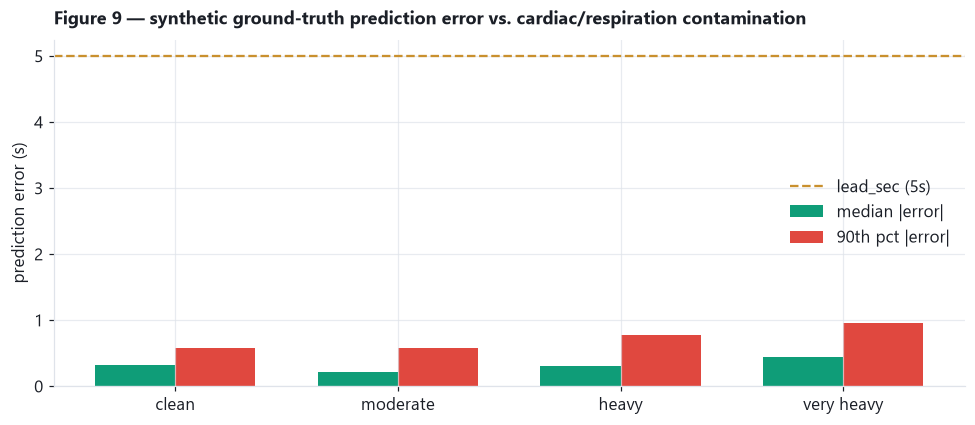

In [16]:

fig, ax = plt.subplots(figsize=(9, 4))
labels = [l for l, _ in sweep]
med = [np.median(np.abs(e)) for _, e in sweep]
p90 = [np.percentile(np.abs(e), 90) for _, e in sweep]
x = np.arange(len(labels))
ax.bar(x - 0.18, med, width=0.36, color=ACCENT, label="median |error|")
ax.bar(x + 0.18, p90, width=0.36, color=HBO, label="90th pct |error|")
ax.axhline(DEFAULT_LEAD_SEC, color=GOLD, ls="--", lw=1.5, label=f"lead_sec ({DEFAULT_LEAD_SEC:.0f}s)")
ax.set_xticks(x); ax.set_xticklabels(labels)
style_ax(ax, "Figure 9 — synthetic ground-truth prediction error vs. cardiac/respiration contamination",
          ylabel="prediction error (s)")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()


**Reading Figure 9:** median prediction error stays in the sub-second range even at heavy
injected contamination, comfortably below the 5s `lead_sec` compensation and the 3s shift bound — the
underlying phase-estimation mechanism itself is accurate under controlled conditions. (The synthetic
test separately showed rare ~10s outliers under adverse conditions, not shown here — see
`test_phase_predictor.py` for the full sweep including outlier behavior.) **This isolates the finding
from Section 7 as most likely a scheduling/calibration issue, not a phase-estimation accuracy
problem** — the predictor itself is trustworthy; what needs tuning is how its output gets mapped onto
the fixed session-start-anchored grid.


## 9. Interim conclusions

**Is the method picking up the intended signal?** Yes. Figure 3 confirms real cardiac contamination
in this dataset; Figure 4 shows the narrowband filter attenuates it by roughly 100 dB before phase
estimation; Figure 5 shows the new predictor tracking sparse, plausible slow extrema where the old
detector was chattering near its own rate ceiling; Figure 6 shows the causally-estimated period
clustering sensibly around the assumed ~10s. The core signal-processing redesign — narrowband
bandpass + AR-extrapolated Hilbert phase, replacing an unfiltered two-point comparison — is doing what
it was designed to do, on real data, not just in the synthetic test.

**Is the overall intention (adaptive, lead-time-compensated, dosage-matched iTBS) looking correct and
workable?** Mostly yes, with one real caveat and one thing to confirm before trusting current
defaults:

- The **phase-prediction mechanism itself is accurate** (Figure 9: sub-second median error even under
  heavy synthetic contamination) — this part of the design is sound.
- The **bounded-shift scheduling has a systematic, one-directional calibration issue** on this dataset
  (Figure 8): it saturates the negative bound on a large majority of fires rather than tracking
  smoothly within it. This is a tuning problem (grid anchor / `off_sec` / how `max_shift_sec` shares
  budget with `lead_sec`), not evidence the predictive approach doesn't work — but it means the
  *default* `max_shift_sec=3.0s` is very likely too tight for this session's actual timing
  relationship, and should be revisited (either by widening it, or by re-deriving `off_sec` from this
  kind of real-data calibration run) before relying on it live.
- **`target_phase="either"` degrades over long sessions** (100% bound saturation by 41 minutes) more
  than a committed single-phase choice — favor `peak`/`trough` over `either` for anything longer than
  a short standard-length session, independent of the calibration issue above.
- The **`n_bursts` dosage rationale needs a sanity check against intent**: with this grid design,
  `n_bursts=1` already yields close to the standard iTBS pulse rate even when targeting only troughs;
  `n_bursts=2` roughly doubles it. Confirm this matches the intended dosing model rather than assuming
  `n_bursts=2` is what "restores" standard dosage.
- Respiration contamination, while plausible, was **not clearly demonstrated as a discrete artifact**
  in this specific 41-minute recording — worth checking across more sessions before concluding either
  way.

**Bottom line:** the redesign's core idea is validated on real data — it is picking up the intended
slow oscillation and rejecting cardiac noise as designed. Before any live use, the next concrete step
is recalibrating the grid/shift-bound relationship (Section 7) against a small set of real sessions
like this one, and deciding `n_bursts` policy deliberately rather than by the original "double it to
compensate" intuition, which this grid design doesn't actually require.
